# Tutorial 11 — A Small Language Model: From Text to Tokens and Back

This notebook runs a pretrained language model locally. It does **not** call a paid API and does **not** train or fine-tune the model. The goal is to see that a language model is still a neural network: it receives tensors, produces logits, and repeatedly selects a token class.

## Learning objectives

By the end of the notebook, you should be able to:

1. convert text into token IDs and decode token IDs back into text;
2. identify the input, embedding and output-logit shapes;
3. inspect the probability distribution for the next token;
4. implement a short greedy next-token loop;
5. use `model.generate()` and compare deterministic and sampled decoding;
6. explain how chat roles are converted into ordinary text tokens.

## Open this notebook

- **Google Colab:** run the setup cell first. The model is downloaded from Hugging Face the first time and then kept in the Colab cache for the current runtime.
- **Your own computer:** open the notebook from this lesson folder. A CPU is sufficient; a GPU or Apple Silicon accelerator is faster.

The model is approximately 0.4 billion parameters. Keep the generated responses short: the purpose is to inspect inference, not to benchmark a chatbot.

In [1]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "11 Large Language Models"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    lesson_path = repo / LESSON_DIR
    if not lesson_path.exists():
        raise FileNotFoundError(f"Lesson folder not found: {lesson_path}")
    os.chdir(lesson_path)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())

Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/11 Large Language Models


## 0. Check the packages

The cell installs `transformers` when it is missing or its version is incompatible. PyTorch stores the model and tensors; Transformers supplies the tokenizer, model definition and generation helper.

In [2]:
from importlib.metadata import PackageNotFoundError, version
from packaging.requirements import Requirement
import subprocess
import sys

required_packages = {
    "transformers": "transformers>=4.57,<5",
}

install_requirements = []
for package, requirement_text in required_packages.items():
    requirement = Requirement(requirement_text)
    try:
        installed_version = version(package)
    except PackageNotFoundError:
        install_requirements.append(requirement_text)
        continue
    if not requirement.specifier.contains(installed_version, prereleases=True):
        install_requirements.append(requirement_text)

if install_requirements:
    print("Installing or updating:", install_requirements)
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        *install_requirements,
    ])
else:
    print("Required packages are already installed.")

import numpy as np
import pandas as pd
pd.set_option("display.max_colwidth", None)
import matplotlib.pyplot as plt
import torch
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer

print("torch", torch.__version__)
print("transformers", transformers.__version__)
print("ready")

Required packages are already installed.
torch 2.5.0
transformers 4.57.6
ready


## 1. Load one small pretrained language model

`SmolLM2-360M-Instruct` is an instruction-tuned causal language model. The same weights are used throughout the tutorial and exercise. The model is placed on CUDA, Apple MPS or CPU automatically.

Inference uses existing parameters. There is no optimizer, loss calculation, backward pass or parameter update.

In [3]:
MODEL_NAME = "HuggingFaceTB/SmolLM2-360M-Instruct"

if torch.cuda.is_available():
    device = torch.device("cuda")
    model_dtype = torch.float16
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    model_dtype = torch.float16
else:
    device = torch.device("cpu")
    model_dtype = torch.float16

print("Loading", MODEL_NAME)
print("Device:", device)
print("Model dtype:", model_dtype)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=model_dtype,
)
model.to(device)
model.eval()

model.generation_config.do_sample = False
model.generation_config.temperature = None
model.generation_config.top_p = None
model.generation_config.top_k = None

if tokenizer.pad_token_id is None:
    tokenizer.pad_token_id = tokenizer.eos_token_id

parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f"Parameters: {parameter_count / 1e6:,.1f} million")
print("Vocabulary size:", model.config.vocab_size)
print("Transformer layers:", model.config.num_hidden_layers)
print("No training will be performed: model.eval() and torch.inference_mode() are used.")

Loading HuggingFaceTB/SmolLM2-360M-Instruct
Device: mps
Model dtype: torch.float16
Parameters: 361.8 million
Vocabulary size: 49152
Transformer layers: 32
No training will be performed: model.eval() and torch.inference_mode() are used.


In [4]:
COLORS = ["#4C78A8", "#F58518", "#54A24B", "#B279A2"]
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

## 2. Text becomes token IDs

A token is a vocabulary item. It may be a word, part of a word, punctuation, a Chinese character, or a piece containing a leading space. The tokenizer maps each piece to an integer ID. The ID is an index, not a semantic measurement.

In [5]:
examples = [
    "Traffic congestion affects travel time.",
    "香港的交通流量正在增加。",
    "We study AI for transport applications.",
]

summary_rows = []
for text in examples:
    token_ids = tokenizer.encode(text, add_special_tokens=False)
    summary_rows.append({
        "text": text,
        "characters": len(text),
        "tokens": len(token_ids),
    })

display(pd.DataFrame(summary_rows))

text = examples[0]
token_ids = tokenizer.encode(text, add_special_tokens=False)
token_table = pd.DataFrame({
    "position": range(len(token_ids)),
    "token_id": token_ids,
    "raw_token": tokenizer.convert_ids_to_tokens(token_ids),
    "decoded_piece": [repr(tokenizer.decode([token_id])) for token_id in token_ids],
})

print("Original text:", text)
display(token_table)
print("Decoded again:", tokenizer.decode(token_ids))

,text,characters,tokens
0,Traffic congestion affects travel time.,39,7
1,香港的交通流量正在增加。,12,22
2,We study AI for transport applications.,39,7


Original text: Traffic congestion affects travel time.


,position,token_id,raw_token,decoded_piece
0,0,8509,Tra,'Tra'
1,1,2046,ffic,'ffic'
2,2,19678,Ġcongestion,' congestion'
3,3,5547,Ġaffects,' affects'
4,4,2827,Ġtravel,' travel'
5,5,655,Ġtime,' time'
6,6,30,.,'.'


Decoded again: Traffic congestion affects travel time.


### Tokenizer input shape: one row per text, one column per token position

The tokenizer must return a rectangular tensor before several texts can enter the model together. Suppose a batch contains $N$ texts and the longest tokenized text contains $L$ tokens:

- `input_ids` has shape `(N, L)`. Row $i$ represents text $i$; column $j$ represents token position $j$. Each entry is a vocabulary lookup index, not a numerical feature value.
- Shorter texts do not naturally have $L$ tokens, so the tokenizer appends a special padding ID until every row has the same length. This operation is **padding**.
- `attention_mask` has the same `(N, L)` shape. A value of `1` marks a real input token; `0` marks padding that the model should ignore.

Therefore, shape `(3, 22)` means **three input texts**, each stored in a row of **22 token positions** because the longest text in this batch uses 22 tokens. The repeated value `2` visible in a shorter row is this tokenizer's padding ID; padding IDs are model-specific and should not be guessed.

> `attention_mask` here is the input padding mask. A causal language model also creates a causal mask internally so a position cannot look at future tokens; the model combines these two restrictions during self-attention.

In [6]:
batch = tokenizer(
    examples,
    padding=True,
    return_tensors="pt",
)

number_of_texts, padded_length = batch["input_ids"].shape
real_token_counts = batch["attention_mask"].sum(dim=1).tolist()

print("input_ids shape     :", tuple(batch["input_ids"].shape), "= (number of texts, padded token positions)")
print("attention_mask shape:", tuple(batch["attention_mask"].shape), "= the same rectangle")
print("pad token           :", repr(tokenizer.pad_token))
print("pad token ID        :", tokenizer.pad_token_id)

batch_summary = pd.DataFrame({
    "row": np.arange(number_of_texts),
    "text": examples,
    "real token positions (mask = 1)": real_token_counts,
    "padding positions (mask = 0)": [padded_length - count for count in real_token_counts],
})
display(batch_summary)

row = 0
row_ids = batch["input_ids"][row].tolist()
row_mask = batch["attention_mask"][row].tolist()
position_table = pd.DataFrame({
    "position": np.arange(padded_length),
    "token_id": row_ids,
    "token piece": [
        repr(tokenizer.decode([token_id])) if mask == 1 else "<PAD>"
        for token_id, mask in zip(row_ids, row_mask)
    ],
    "attention_mask": row_mask,
    "model uses this position?": ["yes" if mask == 1 else "no" for mask in row_mask],
})
print(f"Detailed view of row {row}: {examples[row]!r}")
display(position_table)
print("The padding ID is repeated only to make a rectangle; mask = 0 tells the model not to use those positions.")

input_ids shape     : (3, 22) = (number of texts, padded token positions)
attention_mask shape: (3, 22) = the same rectangle
pad token           : '<|im_end|>'
pad token ID        : 2


,row,text,real token positions (mask = 1),padding positions (mask = 0)
0,0,Traffic congestion affects travel time.,7,15
1,1,香港的交通流量正在增加。,22,0
2,2,We study AI for transport applications.,7,15


Detailed view of row 0: 'Traffic congestion affects travel time.'


,position,token_id,token piece,attention_mask,model uses this position?
0,0,8509,'Tra',1,yes
1,1,2046,'ffic',1,yes
2,2,19678,' congestion',1,yes
3,3,5547,' affects',1,yes
4,4,2827,' travel',1,yes
5,5,655,' time',1,yes
6,6,30,'.',1,yes
7,7,2,<PAD>,0,no
8,8,2,<PAD>,0,no
9,9,2,<PAD>,0,no


The padding ID is repeated only to make a rectangle; mask = 0 tells the model not to use those positions.


## 3. Token IDs become vectors; the model returns logits

The embedding layer looks up one vector for each token ID. The Transformer processes those vectors and the final language-model head returns one score for every vocabulary token at every sequence position.

`input_ids (N, L)` → `embeddings (N, L, d)` → `logits (N, L, V)`

The dimensions mean:

- **N — number of texts in the batch.** For three input sentences, $N=3$.
- **L — number of token positions per text.** Shorter texts are padded so every row has the same length.
- **d — length of each token vector inside the model.** Every token ID is converted into $d$ numerical features.
- **V — vocabulary size.** At each position, the model outputs $V$ logits: one score for every possible next token.

For next-token generation, we read the $V$ scores at the final real token position and convert them into probabilities.

In [7]:
prompt = "Traffic congestion can be reduced by"
model_inputs = tokenizer(prompt, return_tensors="pt")
model_inputs = {name: value.to(device) for name, value in model_inputs.items()}

with torch.inference_mode():
    embeddings = model.get_input_embeddings()(model_inputs["input_ids"])
    model_output = model(**model_inputs, use_cache=False)
    logits = model_output.logits

print("Prompt:", prompt)
print("input_ids shape:", tuple(model_inputs["input_ids"].shape), "= (batch, tokens)")
print("embedding shape:", tuple(embeddings.shape), "= (batch, tokens, model dimension)")
print("logits shape   :", tuple(logits.shape), "= (batch, tokens, vocabulary classes)")

Prompt: Traffic congestion can be reduced by
input_ids shape: (1, 7) = (batch, tokens)
embedding shape: (1, 7, 960) = (batch, tokens, model dimension)
logits shape   : (1, 7, 49152) = (batch, tokens, vocabulary classes)


## 4. One position is a large classification problem

For the next token, we use only the logits at the last input position. Softmax turns those scores into probabilities over the vocabulary. This is analogous to classification, except that the number of classes is the vocabulary size.

,token_id,token_piece,probability
0,22051,' optimizing',0.153138
1,8127,' implementing',0.150764
2,5188,' promoting',0.084571
3,5418,' improving',0.054603
4,2474,' increasing',0.035254
5,4345,' reducing',0.028774
6,8037,' encouraging',0.028328
7,1015,' using',0.024999
8,2194,' building',0.022762
9,11650,' investing',0.020087


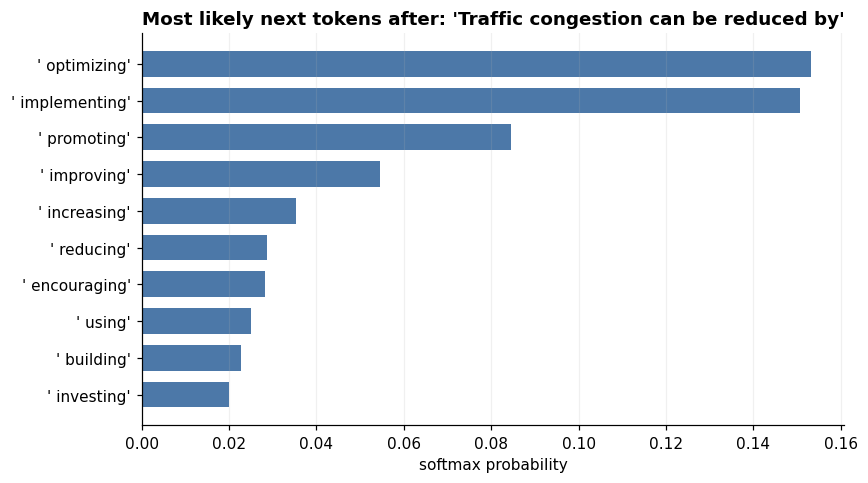

29

In [8]:
next_token_logits = logits[0, -1].float()
next_token_probabilities = torch.softmax(next_token_logits, dim=-1)
top_probabilities, top_ids = torch.topk(next_token_probabilities, 10)

candidate_table = pd.DataFrame({
    "token_id": top_ids.cpu().numpy(),
    "token_piece": [repr(tokenizer.decode([token_id])) for token_id in top_ids],
    "probability": top_probabilities.cpu().numpy(),
})
display(candidate_table)

plot_table = candidate_table.sort_values("probability")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(plot_table.token_piece, plot_table.probability, color=COLORS[0], height=.7)
ax.set(
    xlabel="softmax probability",
    title=f"Most likely next tokens after: {prompt!r}",
)
ax.grid(axis="x", alpha=.18)
fig.tight_layout()
plt.show()

del model_output, embeddings, logits
del next_token_logits, next_token_probabilities
import gc
gc.collect()

## 5. Write the generation loop ourselves

The simplest decoder repeats four operations:

1. run the model on the tokens available so far;
2. take the logits at the last position;
3. choose one token ID;
4. append that ID and repeat.

Greedy decoding chooses the largest logit. It is deterministic but not necessarily the best text-generation strategy.

In [9]:
messages = [
    {"role": "system", "content": "Answer in one short sentence."},
    {"role": "user", "content": "Why are traffic signals used?"},
]
formatted_prompt = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)
input_ids = tokenizer(formatted_prompt, return_tensors="pt")["input_ids"].to(device)
prompt_length = input_ids.shape[1]

step_rows = []
for step in range(16):
    with torch.inference_mode():
        next_logits = model(input_ids=input_ids, use_cache=False).logits[:, -1, :]
    next_token_id = next_logits.argmax(dim=-1)
    input_ids = torch.cat([input_ids, next_token_id[:, None]], dim=1)

    token_id = int(next_token_id.item())
    step_rows.append({
        "step": step + 1,
        "token_id": token_id,
        "decoded_piece": repr(tokenizer.decode([token_id])),
    })
    if token_id == tokenizer.eos_token_id:
        break

display(pd.DataFrame(step_rows))
new_token_ids = input_ids[0, prompt_length:]
print("Generated text:")
print(tokenizer.decode(new_token_ids, skip_special_tokens=True))

del input_ids, next_logits
gc.collect()

,step,token_id,decoded_piece
0,1,8509,'Tra'
1,2,2046,'ffic'
2,3,6247,' signals'
3,4,359,' are'
4,5,804,' used'
5,6,288,' to'
6,7,4511,' manage'
7,8,5442,' traffic'
8,9,1874,' flow'
9,10,411,' by'


Generated text:
Traffic signals are used to manage traffic flow by directing vehicles to the correct intersections


0

## 6. `generate()` performs the same loop conveniently

Transformers provides `model.generate()` so we do not need to write the loop every time. `max_new_tokens` is a maximum number of **new tokens after the prompt**; it is not a word count, and generation may stop earlier when the end-of-sequence token is produced. For a decoder-only model, the returned sequence contains both the prompt and the new tokens, so we slice away the prompt before decoding the answer.

When `do_sample=False`, generation is greedy and deterministic: `temperature` and `top_p` are not used. When `do_sample=True`, the model samples one next token from a filtered probability distribution; then `temperature`, `top_p` and the random `seed` matter.

In [10]:
def prepare_chat_inputs(user_message, system_message="Answer clearly and briefly."):
    messages = [
        {"role": "system", "content": system_message},
        {"role": "user", "content": user_message},
    ]
    formatted_text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    model_inputs = tokenizer(formatted_text, return_tensors="pt")
    model_inputs = {name: value.to(device) for name, value in model_inputs.items()}
    return model_inputs, formatted_text


def generate_reply(
    user_message,
    system_message="Answer clearly and briefly.",
    max_new_tokens=60,
    do_sample=False,
    temperature=0.8,
    top_p=0.9,
    seed=42,
):
    model_inputs, _ = prepare_chat_inputs(user_message, system_message)
    generation_options = {
        "max_new_tokens": max_new_tokens,
        "do_sample": do_sample,
        "pad_token_id": tokenizer.eos_token_id,
        "use_cache": False,  # keeps this teaching notebook memory-safe on CPU
    }
    if do_sample:
        generation_options.update({
            "temperature": temperature,
            "top_p": top_p,
        })

    torch.manual_seed(seed)
    with torch.inference_mode():
        output_ids = model.generate(
            **model_inputs,
            **generation_options,
        )

    input_length = model_inputs["input_ids"].shape[1]
    new_token_ids = output_ids[0, input_length:]
    return tokenizer.decode(new_token_ids, skip_special_tokens=True).strip()


def next_token_candidates(text, number_to_show=10, temperature=1.0):
    model_inputs = tokenizer(text, return_tensors="pt")
    model_inputs = {name: value.to(device) for name, value in model_inputs.items()}
    with torch.inference_mode():
        logits = model(**model_inputs, use_cache=False).logits
    probabilities = torch.softmax(logits[0, -1].float() / temperature, dim=-1)
    top_probabilities, top_ids = torch.topk(probabilities, number_to_show)
    return pd.DataFrame({
        "token_id": top_ids.cpu().numpy(),
        "token_piece": [repr(tokenizer.decode([token_id])) for token_id in top_ids],
        "probability": top_probabilities.cpu().numpy(),
    })

In [11]:
question = "Explain in one sentence what traffic congestion means."
reply = generate_reply(
    question,
    system_message="You are a transportation engineering tutor. Use one short sentence.",
    max_new_tokens=45,
)

print("User:", question)
print("Model:", reply)

User: Explain in one sentence what traffic congestion means.
Model: Traffic congestion refers to the condition of having too many vehicles on a road, making it difficult for drivers to move at a reasonable speed, leading to increased travel times and decreased efficiency.


## 7. Chat roles are still tokens

`system`, `user` and `assistant` are not additional neural-network input channels. `apply_chat_template()` converts the messages into a single formatted string containing special markers. That string is then tokenized like any other text.

In [12]:
chat_inputs, formatted_chat = prepare_chat_inputs(
    "What is a token?",
    "Answer for a first-year engineering student.",
)

print("Formatted chat text sent to the tokenizer:\n")
print(formatted_chat)
print("\nTensor shape:", tuple(chat_inputs["input_ids"].shape))
print("The visible roles above become ordinary token IDs before entering the model.")

Formatted chat text sent to the tokenizer:

<|im_start|>system
Answer for a first-year engineering student.<|im_end|>
<|im_start|>user
What is a token?<|im_end|>
<|im_start|>assistant


Tensor shape: (1, 28)
The visible roles above become ordinary token IDs before entering the model.


## 8. Generation settings control next-token selection

At generation step $t$, the model produces one logit $z_j$ for every possible next token $j$. Generation temperature rescales these **final output logits** before sampling:

$$
p_T(w_j\mid w_{<t})=\frac{\exp(z_j/T)}{\sum_k \exp(z_k/T)}.
$$

- $T<1$ makes the distribution sharper, so high-probability tokens are selected more often.
- $T=1$ leaves the model distribution unchanged.
- $T>1$ makes the distribution flatter and increases sampling variety.
- Greedy decoding uses $\arg\max_j z_j$ rather than sampling, so positive temperature scaling does not change its selected token.

### Nucleus sampling with `top_p`

Sort the next-token probabilities from largest to smallest, $p_{(1)}\ge p_{(2)}\ge\cdots$. Nucleus sampling retains the smallest candidate set $S_p$ whose cumulative probability reaches the threshold:

$$
K=\min\left\{m:\sum_{i=1}^{m}p_{(i)}\ge p\right\},\qquad S_p=\{w_{(1)},\ldots,w_{(K)}\}.
$$

Probabilities outside $S_p$ are set to zero; the retained probabilities are renormalised to sum to one before sampling. A lower `top_p` usually retains fewer, safer candidates; a higher `top_p` admits more of the tail. Unlike `top_k`, which always keeps exactly $k$ candidates, the number retained by `top_p` changes with the model's confidence.

### Parameter summary

| Setting | What it controls | Important detail |
|---|---|---|
| `do_sample` | token-selection rule | `False`: greedy argmax; `True`: random sampling |
| `temperature` | sharpness of all next-token probabilities | used only when sampling |
| `top_p` | cumulative-probability candidate set | dynamic number of retained tokens |
| `top_k` | highest-probability candidate set | fixed number $k$ of retained tokens |
| `max_new_tokens` | output-length cap | counts tokens after the prompt, not words |
| `seed` | random-number sequence | helps reproduce sampling; does not change model weights or logits |

This is a decoding setting applied after the language model produces logits. It is not the $1/\sqrt{d_k}$ scaling used inside an attention layer, and it does not retrain the model.

,temperature,token_id,token_piece,probability
0,0.4,2705,'One',0.998417
1,0.4,49,'A',0.001304
2,0.4,16865,'Consider',0.000085
3,0.4,41457,'Reducing',0.000071
4,0.4,43077,'Implement',0.000055
5,1.0,2705,'One',0.741970
6,1.0,49,'A',0.052094
7,1.0,16865,'Consider',0.017449
8,1.0,41457,'Reducing',0.016265
9,1.0,43077,'Implement',0.014694


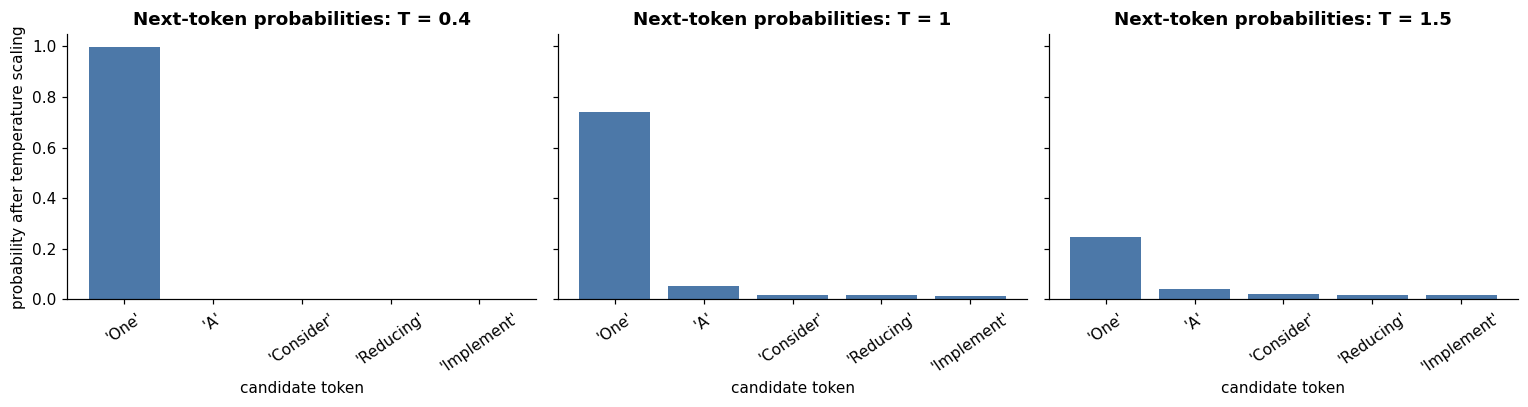

,top_p,retained candidate tokens,probability mass before renormalising,highest-probability retained pieces
0,0.50,1,0.741970,'One'
1,0.80,3,0.811513,'One' | 'A' | 'Consider'
2,0.95,68,0.950124,'One' | 'A' | 'Consider' | 'Reducing' | 'Implement' | '1'


,method,output
0,greedy (no sampling),One practical idea for reducing peak-hour traffic is to implement a smart traffic management system that optimizes traffic signal timing and routing to minimize congestion during peak hours. This can be achieved by using real-time data from traffic sensors
1,"sampling: T=0.4, top_p=1.0","One practical idea for reducing peak-hour traffic is to implement a smart traffic management system that optimizes traffic signal timing, reduces congestion, and provides real-time traffic updates to drivers. This can be achieved through the use of"
2,"sampling: T=1.5, top_p=1.0",Plan l varieties Limpool Hob lemonade################|'Slomp': for traveling guests who re woid consumers accustomed to Australian winesDuring Brisbane Holiday Tem rights detectors condensation##On monarch cpastic Hadmonococca sc \n\nJ


In [13]:
generation_prompt = "Give one practical idea for reducing peak-hour traffic."
_, generation_text = prepare_chat_inputs(generation_prompt)
temperature_rows = []
for temperature in [0.4, 1.0, 1.5]:
    candidates = next_token_candidates(
        generation_text, number_to_show=5, temperature=temperature
    )
    candidates.insert(0, "temperature", temperature)
    temperature_rows.append(candidates)

temperature_table = pd.concat(temperature_rows, ignore_index=True)
display(temperature_table)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, temperature in zip(axes, [0.4, 1.0, 1.5]):
    group = temperature_table[temperature_table.temperature.eq(temperature)]
    ax.bar(group.token_piece, group.probability, color=COLORS[0])
    ax.set_title(f"Next-token probabilities: T = {temperature:g}")
    ax.set_xlabel("candidate token")
    ax.tick_params(axis="x", rotation=35)
axes[0].set_ylabel("probability after temperature scaling")
plt.tight_layout()
plt.show()

# Show how top_p changes the size of the candidate set at T = 1.
nucleus_inputs = tokenizer(generation_text, return_tensors="pt")
nucleus_inputs = {name: value.to(device) for name, value in nucleus_inputs.items()}
with torch.inference_mode():
    nucleus_logits = model(**nucleus_inputs, use_cache=False).logits[0, -1].float()
nucleus_probabilities = torch.softmax(nucleus_logits, dim=-1)
sorted_probabilities, sorted_ids = torch.sort(nucleus_probabilities, descending=True)
cumulative_probabilities = sorted_probabilities.cumsum(dim=0)

nucleus_rows = []
for top_p in [0.50, 0.80, 0.95]:
    cutoff = int(torch.searchsorted(
        cumulative_probabilities,
        torch.tensor(top_p, device=cumulative_probabilities.device),
    ).item()) + 1
    preview_ids = sorted_ids[:min(cutoff, 6)].tolist()
    nucleus_rows.append({
        "top_p": top_p,
        "retained candidate tokens": cutoff,
        "probability mass before renormalising": float(cumulative_probabilities[cutoff - 1]),
        "highest-probability retained pieces": " | ".join(
            repr(tokenizer.decode([token_id])) for token_id in preview_ids
        ),
    })
display(pd.DataFrame(nucleus_rows))

generation_rows = [{
    "method": "greedy (no sampling)",
    "output": generate_reply(generation_prompt, max_new_tokens=45),
}]
for temperature in [0.4, 1.5]:
    generation_rows.append({
        "method": f"sampling: T={temperature}, top_p=1.0",
        "output": generate_reply(
            generation_prompt, max_new_tokens=45, do_sample=True,
            temperature=temperature, top_p=1.0, seed=7,
        ),
    })
display(pd.DataFrame(generation_rows))

## 9. Three small inference tasks

The same next-token model can respond to different instructions because the instruction changes the input context. These demonstrations are deliberately short. This 0.36B-parameter model is useful for learning the mechanics, but its factual knowledge and instruction following are limited.

In [14]:
tasks = [
    {
        "task": "explanation",
        "prompt": "Explain in two short sentences what a token is in a language model.",
    },
    {
        "task": "structured extraction",
        "prompt": (
            "Convert this note to JSON with keys component, condition and action. "
            "Note: component = deck; condition = several small cracks; "
            "action = schedule a detailed inspection."
        ),
    },
    {
        "task": "short summary",
        "prompt": (
            "Summarise in two bullet points: Traffic sensors measure flow and speed. "
            "These measurements support congestion monitoring and short-term forecasting."
        ),
    },
]

task_outputs = []
for task in tasks:
    task_outputs.append({
        "task": task["task"],
        "model output": generate_reply(
            task["prompt"],
            system_message="Follow the requested format and keep the response short.",
            max_new_tokens=80,
        ),
    })

display(pd.DataFrame(task_outputs))

,task,model output
0,explanation,"A token in a language model is a unique identifier assigned to each word or phrase in a sentence, allowing the model to distinguish between different words and phrases."
1,structured extraction,"{\n ""component"": ""deck"",\n ""condition"": ""several small cracks"",\n ""action"": ""schedule a detailed inspection""\n}"
2,short summary,* Traffic sensors measure flow and speed\n* These measurements support congestion monitoring and short-term forecasting


## 10. Probability of each generated token

`generate()` can return the score used at every generation step. This lets us connect the final text back to repeated token classification. A high probability means the selected token was strongly preferred under this model and context; it does not guarantee that the statement is factually correct.

,step,token_id,token_piece,selected_token_probability
0,1,1195,'the',0.222738
1,2,2619,' condition',0.291434
2,3,282,' of',0.883416
3,4,253,' a',0.451216
4,5,7395,' bridge',0.891460
5,6,506,"""'s""",0.310765
6,7,2678,' structure',0.367830
7,8,284,' and',0.573139
8,9,624,' its',0.186346
9,10,3962,' connections',0.161091


Decoded output: the condition of a bridge's structure and its connections.


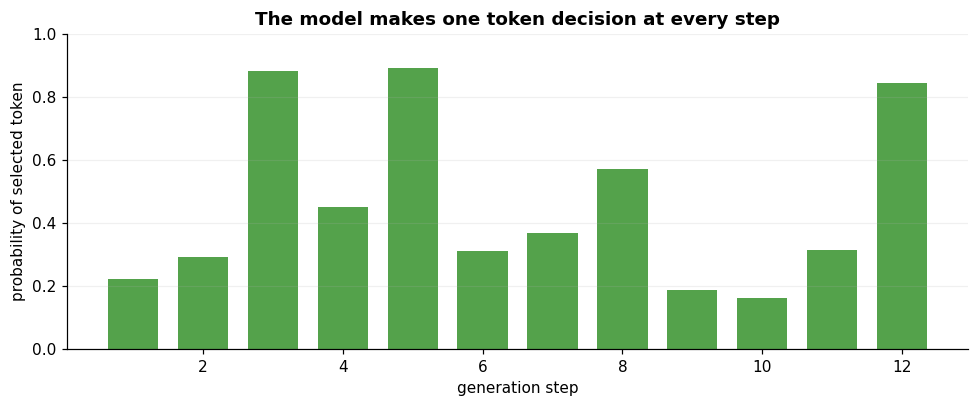

In [15]:
score_inputs, _ = prepare_chat_inputs(
    "Complete briefly: A bridge inspection checks",
    "Complete the sentence with a short list.",
)

with torch.inference_mode():
    generation = model.generate(
        **score_inputs,
        max_new_tokens=14,
        do_sample=False,
        return_dict_in_generate=True,
        output_scores=True,
        pad_token_id=tokenizer.eos_token_id,
        use_cache=False,
    )

transition_log_probabilities = model.compute_transition_scores(
    generation.sequences,
    generation.scores,
    normalize_logits=True,
)[0]
input_length = score_inputs["input_ids"].shape[1]
generated_ids = generation.sequences[0, input_length:]

score_table = pd.DataFrame({
    "step": range(1, len(generated_ids) + 1),
    "token_id": generated_ids.cpu().numpy(),
    "token_piece": [repr(tokenizer.decode([token_id])) for token_id in generated_ids],
    "selected_token_probability": transition_log_probabilities.exp().cpu().numpy(),
})
display(score_table)
print("Decoded output:", tokenizer.decode(generated_ids, skip_special_tokens=True))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(score_table.step, score_table.selected_token_probability, color=COLORS[2], width=.72)
ax.set(
    xlabel="generation step",
    ylabel="probability of selected token",
    title="The model makes one token decision at every step",
    ylim=(0, 1),
)
ax.grid(axis="y", alpha=.18)
fig.tight_layout()
plt.show()

## What to remember

1. Text is converted to integer token IDs; embedding lookup converts IDs to vectors.
2. A causal language model returns logits of shape `(batch, token positions, vocabulary classes)`.
3. The last-position logits define a probability distribution for the next token.
4. Text generation repeatedly selects and appends one token.
5. Generation temperature rescales final next-token logits before sampling; it is not attention scaling and does not retrain the model.
6. A fluent token sequence can still be incomplete or factually wrong.